# Prédiction des prix immobiliers dans le Doubs (DVF 2021–2025)

**Objectif :** prédire le prix de vente d'une maison ou d'un appartement à partir de ses caractéristiques (surface, pièces, terrain, localisation, date).

**Données :** Demandes de Valeurs Foncières géolocalisées (data.gouv.fr), département 25, ventes de 2021 à 2025.

**Démarche :**
1. Nettoyage et construction d'un jeu de données « une ligne = une vente »
2. Analyse exploratoire
3. Création de variables (distances, prix moyen de la commune)
4. Comparaison de modèles : baseline, Ridge, Random Forest, LightGBM
5. Évaluation sur une année jamais vue (2025) et interprétation avec SHAP

**Résultat :** sur 2025 (année jamais vue pendant l'entraînement ni le réglage), LightGBM atteint une erreur absolue moyenne d'environ 41 000 € (erreur relative médiane de 18 %, R² = 0,64), soit 13 % d'erreur en moins qu'une baseline « prix médian de la commune ».

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import KFold, RandomizedSearchCV
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import lightgbm as lgb, shap

SEED = 42
np.random.seed(SEED)            # pour obtenir à chaque fois les mêmes résultats
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110

# Dossier contenant les fichiers DVF du Doubs : ce sont les 25.csv.gz de chaque année, renommés 25_1 (2021), 25_2 (2022), 25_3 (2023), 25_4 (2024), 25_5 (2025)
DATA_DIR = 'data'
FILES = {2021: '25_1', 2022: '25_2', 2023: '25_3', 2024: '25_4', 2025: '25_5'}

## 1. Chargement et nettoyage

In [2]:
# on prend uniquement les colonnes qui seront utiles à l'étude 
use = ['id_mutation','date_mutation','nature_mutation','valeur_fonciere','code_postal','code_commune','nom_commune',
       'id_parcelle','type_local','surface_reelle_bati','nombre_pieces_principales','surface_terrain','longitude','latitude']   
raw = pd.concat([pd.read_csv(f'{DATA_DIR}/{f}.csv.gz', usecols=use, dtype={'code_commune':str,'code_postal':str})
                 for f in FILES.values()], ignore_index=True)
print(f'{len(raw):,} lignes brutes (une ligne = une parcelle ou un local d\'une vente)')
raw.nature_mutation.value_counts()

184,916 lignes brutes (une ligne = une parcelle ou un local d'une vente)


nature_mutation
Vente                                 176831
Vente en l'état futur d'achèvement      4880
Echange                                 2108
Vente terrain à bâtir                    646
Adjudication                             451
Name: count, dtype: int64

Une vente (`id_mutation`) contient plusieurs lignes : le logement, ses dépendances (garage, cave), des terrains.
On garde uniquement les **ventes simples** (`nature_mutation = Vente`) qui contiennent **exactement un logement** (maison ou appartement), pour que le prix corresponde bien à ce logement.
Le terrain est la somme des surfaces de parcelles distinctes de la vente.

In [3]:
v = raw[raw.nature_mutation == 'Vente'].copy()  # on ne garde que les ventes simples
v['date_mutation'] = pd.to_datetime(v.date_mutation)    # transformation des dates pour pouvoir les exploiter

logt = v[v.type_local.isin(['Maison','Appartement'])]
nb_log = logt.groupby('id_mutation').size()
ok_ids = nb_log[nb_log == 1].index
print(f'Ventes avec un logement : {len(nb_log):,} | avec exactement un logement : {len(ok_ids):,}')

# On ne garde que les ventes qui contiennent exactement UN logement (maison ou appartement).
# Raison : le prix (valeur_fonciere) est un montant global pour toute la vente. Si elle contient
# plusieurs logements, on ne sait pas comment le prix se répartit entre eux, et le prix associé
# à chacun serait faux. Avec un seul logement, le prix correspond bien à ce bien.
# Limite : on perd environ 5 400 ventes (immeubles, lots de plusieurs logements).

v = v[v.id_mutation.isin(ok_ids)]

# On garde une ligne par (vente, parcelle) pour ne pas compter une parcelle deux fois, puis on additionne.
terrain = (v.drop_duplicates(['id_mutation','id_parcelle'])
             .groupby('id_mutation').surface_terrain.sum().rename('terrain'))

# Nombre de dépendances (caves, garages) de chaque vente
nb_dep = v[v.type_local == 'Dépendance'].groupby('id_mutation').size().rename('nb_dependances')

df = (v[v.type_local.isin(['Maison','Appartement'])]
        .drop_duplicates('id_mutation')
        .set_index('id_mutation')
        .join(terrain).join(nb_dep)
        .rename(columns={'valeur_fonciere':'prix','surface_reelle_bati':'surface','nombre_pieces_principales':'pieces'}))
df['nb_dependances'] = df.nb_dependances.fillna(0)   # pas de dépendance = 0
df['annee'] = df.date_mutation.dt.year
df['mois_depuis_2021'] = (df.annee-2021)*12 + df.date_mutation.dt.month   # temps continu (en mois) pour capter la tendance des prix
df = df.dropna(subset=['prix','surface','latitude','longitude'])            # inutilisables sans ces 4 infos
df.loc[df.type_local=='Appartement','terrain'] = 0   # le terrain renseigné pour un appartement est celui de l'immeuble, pas du logement
df['terrain'] = df.terrain.fillna(0)    # maisons sans terrain renseigné : on considère 0
df['prix_m2'] = df.prix / df.surface
print(f'{len(df):,} ventes avant filtrage des valeurs aberrantes')

Ventes avec un logement : 38,269 | avec exactement un logement : 32,859
32,553 ventes avant filtrage des valeurs aberrantes


In [4]:
# filtrage pour enlever les valeurs aberrantes (ventes symboliques, erreurs de saisie, biens d'exception)
# Ici on définit le périmètre de l'étude : biens de 20 000 € à 1,5 M€, de 9 à 400 m², etc.
# Le filtre sur le prix au m² (qui dépend du prix à prédire) est appliqué plus bas, sur le train uniquement.
PRIX_MIN, PRIX_MAX = 20_000, 1_500_000
SURF_MIN, SURF_MAX = 9, 400
PIECES_MIN, PIECES_MAX = 1, 10
PM2_MIN, PM2_MAX = 300, 8_000
TERRAIN_MAX = 20_000

n0 = len(df)
df = df[(df.prix.between(PRIX_MIN, PRIX_MAX)) &
        (df.surface.between(SURF_MIN, SURF_MAX)) &
        (df.pieces.between(PIECES_MIN, PIECES_MAX)) &
        (df.terrain <= TERRAIN_MAX)].copy()
print(f'{n0-len(df):,} ventes supprimées (prix, surface, pièces ou terrain aberrants) -> {len(df):,} ventes conservées')
df[['prix','surface','pieces','terrain','prix_m2']].describe().round(0)

405 ventes supprimées (prix, surface, pièces ou terrain aberrants) -> 32,148 ventes conservées


,prix,surface,pieces,terrain,prix_m2
count,32148.0,32148.0,32148.0,32148.0,32148.0
mean,168735.0,83.0,4.0,411.0,2111.0
std,103535.0,38.0,1.0,918.0,1042.0
min,20000.0,9.0,1.0,0.0,98.0
25%,94000.0,60.0,3.0,0.0,1429.0
50%,145750.0,79.0,4.0,0.0,2028.0
75%,222378.0,102.0,5.0,676.0,2667.0
max,1474200.0,400.0,10.0,19530.0,26440.0


## 2. Analyse exploratoire

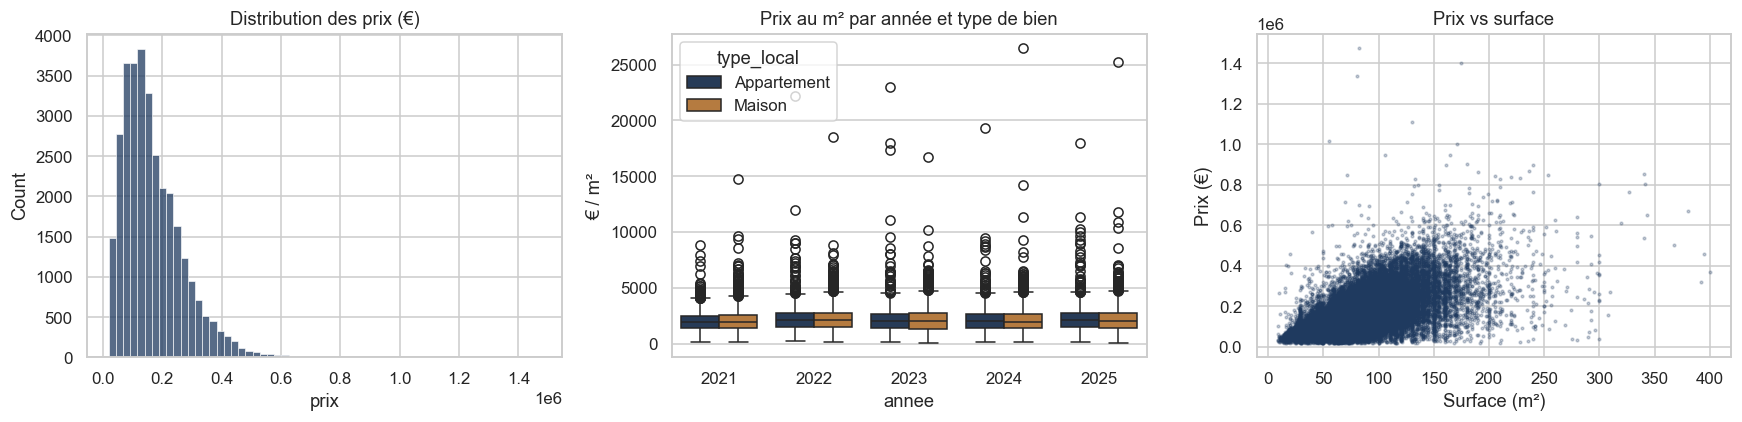

                 count             median        
type_local Appartement Maison Appartement  Maison
annee                                            
2021              4016   3278      1921.0  1951.0
2022              4121   3119      2095.0  2094.0
2023              3443   2524      2020.0  2031.0
2024              3117   2393      2027.0  1969.0
2025              3453   2684      2150.0  2044.0


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df.prix, bins=60, ax=ax[0], color='#1f3a5f'); ax[0].set_title('Distribution des prix (€)')
sns.boxplot(data=df, x='annee', y='prix_m2', hue='type_local', ax=ax[1], palette=['#1f3a5f','#c97b2c'])
ax[1].set_title('Prix au m² par année et type de bien'); ax[1].set_ylabel('€ / m²')
ax[2].scatter(df.surface, df.prix, s=3, alpha=.25, color='#1f3a5f'); ax[2].set_xlabel('Surface (m²)'); ax[2].set_ylabel('Prix (€)')
ax[2].set_title('Prix vs surface')
plt.tight_layout(); plt.show()

print(df.groupby(['annee','type_local']).prix_m2.agg(['count','median']).round(0).unstack())

**Ce qu'on observe :** le prix au m² médian est assez stable sur la période (autour de 2 000 €/m²), avec une hausse en 2022 et une remontée des appartements en 2025. Maisons et appartements ont des prix au m² très proches. Le nombre de ventes baisse après 2022 (de 4 121 à 3 117 appartements entre 2022 et 2024) avant de remonter en 2025. Le prix augmente avec la surface, mais la dispersion aussi : à surface égale, les prix varient beaucoup. Il reste des valeurs extrêmes de prix au m² (jusqu'à 26 000 €/m²) : on ne les retire que du jeu d'entraînement, pas du test (voir section 3).

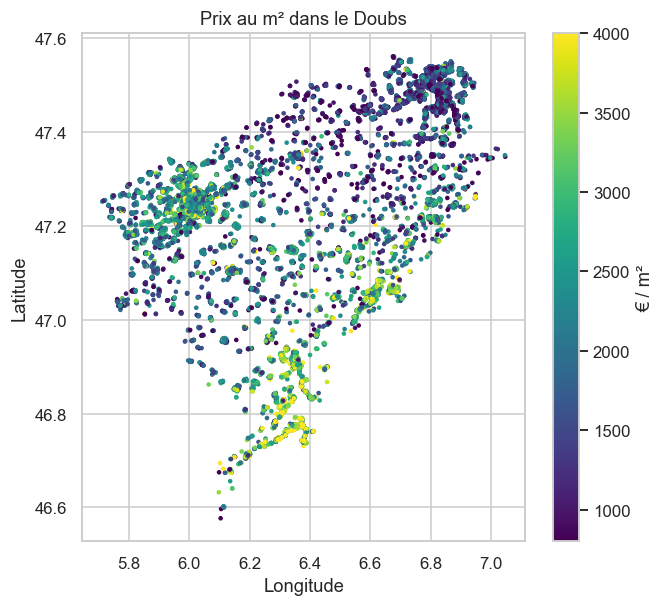

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 6))
sc = ax.scatter(df.longitude, df.latitude, c=df.prix_m2, s=4, cmap='viridis', vmin=800, vmax=4000)
plt.colorbar(sc, label='€ / m²'); ax.set_title('Prix au m² dans le Doubs'); ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
plt.show()

**Ce qu'on observe :** le nord-est du département (autour de Montbéliard) a les prix au m² les plus bas, et le sud (Haut-Doubs, vers Pontarlier et la frontière suisse) les plus élevés. La localisation compte donc beaucoup, d'où les variables de distance et le prix moyen de la commune.

## 3. Création de variables
- **Distances** (km) aux principaux pôles du département : Besançon, Montbéliard, Pontarlier, et à la frontière suisse (Le Locle, proxy du marché des travailleurs frontaliers).
- **Prix moyen de la commune** (en €/m², lissé) calculé **uniquement sur les données d'entraînement** et, pour l'entraînement, en validation croisée (*out-of-fold*), afin d'éviter toute fuite d'information.

In [7]:
# formule de haversine : distance à vol d'oiseau (en km) entre deux points sur la Terre

def haversine(lat1, lon1, lat2, lon2):
    R = 6371; p = np.pi/180
    a = np.sin((lat2-lat1)*p/2)**2 + np.cos(lat1*p)*np.cos(lat2*p)*np.sin((lon2-lon1)*p/2)**2
    return 2*R*np.arcsin(np.sqrt(a))

POLES = {'besancon':(47.2378,6.0241), 'montbeliard':(47.5100,6.7980), 'pontarlier':(46.9040,6.3550), 'frontiere_suisse':(47.0587,6.7491)}
for k,(la,lo) in POLES.items():
    df[f'dist_{k}'] = haversine(df.latitude, df.longitude, la, lo)
df['dist_pole_min'] = df[[f'dist_{k}' for k in ['besancon','montbeliard','pontarlier']]].min(axis=1)    # on calcule la distance entre le bien et les grandes villes et on garde le min
df['is_maison'] = (df.type_local == 'Maison').astype(int)   # maison = 1, appartement = 0 (les modèles ne lisent pas du texte)
df['log_surface'] = np.log(df.surface)      # plus la surface augmente, plus le prix au m² baisse : le log écrase cet effet
df['log_terrain'] = np.log1p(df.terrain)    # ici on utilise log1p pour gérer le cas 0m2
df['y'] = np.log(df.prix)          # on prédit le log du prix
df = df.sort_values('date_mutation')    # Trie les données par ordre chronologique

# Pourquoi le log du prix : les prix sont très asymétriques, le log atténue le poids des biens d'exception
# et transforme l'erreur en erreur relative (en %) plutôt qu'en euros.

# Séparation temporelle : on entraîne sur 2021-2024 et on teste sur 2025 (année jamais vue)
train = df[df.annee <= 2024].copy()
test  = df[df.annee == 2025].copy()

# filtre sur le prix au m² : train uniquement, le test reste tel quel pour une évaluation honnête
train = train[train.prix_m2.between(PM2_MIN, PM2_MAX)].copy()

print(f'Train : {len(train):,} ventes (2021-2024) | Test : {len(test):,} ventes (2025)')

Train : 25,873 ventes (2021-2024) | Test : 6,137 ventes (2025)


In [8]:
# Encodage de la commune : prix/m² médian lissé (target encoding)
SMOOTH = 15     # lissage : une commune avec peu de ventes est tirée vers la médiane globale (comme si on ajoutait SMOOTH ventes au prix médian global)
def fit_commune_enc(tr):        # calcule le prix médian au m2 de chaque commune
    g = tr.groupby('code_commune').prix_m2.agg(['median','count'])
    glob = tr.prix_m2.median()
    enc = (g['median']*g['count'] + glob*SMOOTH) / (g['count'] + SMOOTH)
    return enc, glob

# Train : encodage en out-of-fold. Chaque vente reçoit le prix de sa commune calculé SANS elle-même,
# sinon le prix à prédire fuit dans la variable (target leakage) et le modèle sur-apprend dessus.
train['commune_prix_m2'] = np.nan       # colonne vide pour stocker le prix au m2 encodés
for tr_idx, va_idx in KFold(5, shuffle=True, random_state=SEED).split(train):   # 5 plis mélangés (pas découpés par année, voir limites)
    enc, glob = fit_commune_enc(train.iloc[tr_idx])
    train.iloc[va_idx, train.columns.get_loc('commune_prix_m2')] = train.iloc[va_idx].code_commune.map(enc).fillna(glob).values # commune absente du pli : médiane globale du département
enc_full, glob_full = fit_commune_enc(train)    
test['commune_prix_m2'] = test.code_commune.map(enc_full).fillna(glob_full)   # test : encodage ajusté sur tout le train (commune inconnue : médiane globale)

FEATURES = ['log_surface','pieces','log_terrain','nb_dependances','is_maison','latitude','longitude',
            'dist_besancon','dist_montbeliard','dist_pontarlier','dist_frontiere_suisse','dist_pole_min',
            'commune_prix_m2','mois_depuis_2021']
Xtr, ytr = train[FEATURES], train.y
Xte, yte = test[FEATURES], test.y   # cible = log du prix

## 4. Modèles
Tous les modèles prédisent le **log du prix** (les prix sont très asymétriques), puis on revient en euros pour l'évaluation.

Métriques : **MAE** (erreur moyenne en €), **RMSE**, **R²**, et **MdAPE** (erreur relative médiane, plus parlante pour un acheteur).

In [9]:
def evaluate(name, pred_log, store):
    # les modèles prédisent le log du prix : on repasse en euros avant de calculer les métriques
    p, t = np.exp(pred_log), test.prix.values
    store.append({'Modèle':name,
                  'MAE (€)':mean_absolute_error(t,p),
                  'RMSE (€)':np.sqrt(mean_squared_error(t,p)),
                  'R²':r2_score(t,p),
                  'MdAPE (%)':np.median(np.abs(p-t)/t)*100})
    return p
results, preds = [], {}

# 1) Baseline : prix/m² médian de la commune et du type de bien (train) x surface
med = train.groupby(['code_commune','type_local']).prix_m2.median()
med_type = train.groupby('type_local').prix_m2.median()
pm2 = [med.get((c,t), med_type[t]) for c,t in zip(test.code_commune, test.type_local)]
preds['Baseline (médiane commune)'] = evaluate('Baseline (médiane commune)', np.log(np.array(pm2)*test.surface.values), results)

# 2) Ridge
ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(Xtr, ytr)
preds['Ridge'] = evaluate('Ridge', ridge.predict(Xte), results)

# 3) Random Forest
rf = RandomForestRegressor(n_estimators=400, min_samples_leaf=3, max_features=0.6, n_jobs=-1, random_state=SEED).fit(Xtr, ytr)
preds['Random Forest'] = evaluate('Random Forest', rf.predict(Xte), results)

In [10]:
# 4) LightGBM avec recherche d'hyperparamètres (validation croisée 5 plis sur le train uniquement)
# scoring = MAE sur le log du prix (donc erreur relative) ; le tableau final est lui calculé en euros
param_dist = {'n_estimators':[300,500,800], 'learning_rate':[0.02,0.03,0.05,0.08], 'num_leaves':[15,31,63],
              'min_child_samples':[10,20,40], 'subsample':[0.7,0.85,1.0], 'colsample_bytree':[0.6,0.8,1.0],
              'reg_lambda':[0,1,5]}
search = RandomizedSearchCV(lgb.LGBMRegressor(subsample_freq=1, random_state=SEED, verbose=-1),
                            param_dist, n_iter=20, cv=5, scoring='neg_mean_absolute_error', random_state=SEED, n_jobs=-1)
search.fit(Xtr, ytr)
print('Meilleurs paramètres :', search.best_params_)
gbm = search.best_estimator_
preds['LightGBM'] = evaluate('LightGBM', gbm.predict(Xte), results)

Meilleurs paramètres : {'subsample': 0.85, 'reg_lambda': 5, 'num_leaves': 63, 'n_estimators': 800, 'min_child_samples': 10, 'learning_rate': 0.03, 'colsample_bytree': 0.8}


In [11]:
res = pd.DataFrame(results).set_index('Modèle').round(2)
base = res.loc['Baseline (médiane commune)','MAE (€)']
res['Gain MAE vs baseline (%)'] = ((1 - res['MAE (€)']/base)*100).round(1)
res

,MAE (€),RMSE (€),R²,MdAPE (%),Gain MAE vs baseline (%)
Modèle,,,,,
Baseline (médiane commune),47097.98,70105.42,0.58,22.34,0.0
Ridge,46283.52,68407.35,0.60,21.74,1.7
Random Forest,41854.87,65532.30,0.63,18.68,11.1
LightGBM,41079.98,64353.00,0.64,17.96,12.8


**Lecture :** Ridge améliore à peine la baseline (−1,7 % de MAE) alors que Random Forest et LightGBM font nettement mieux (−11,1 % et −12,8 %). La relation entre les variables et le prix n'est donc pas linéaire. Le gain reste modeste : la baseline « médiane de la commune » est déjà un repère solide (R² = 0,58), car la surface et la localisation expliquent déjà l'essentiel du prix.

## 5. Résultats sur 2025 (données jamais vues)

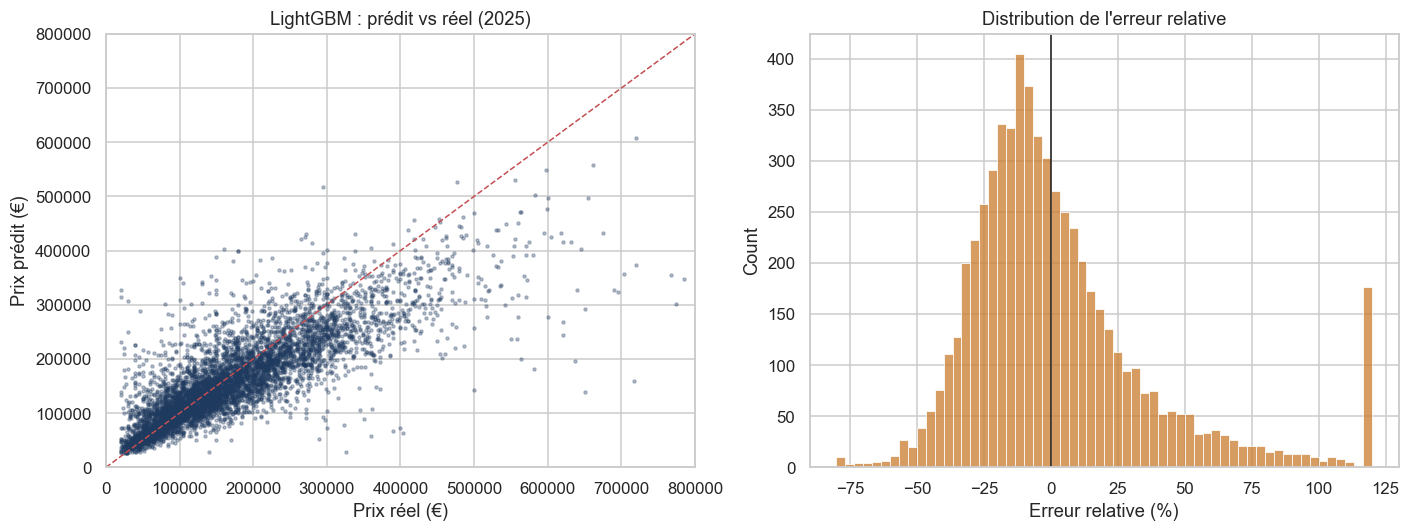

Appartement  MAE =    29,168 €   R² = 0.603   (n = 3453)
Maison       MAE =    56,405 €   R² = 0.567   (n = 2684)


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
best = preds['LightGBM']
ax[0].scatter(test.prix, best, s=4, alpha=.3, color='#1f3a5f')
lim = [0, 800_000]; ax[0].plot(lim, lim, 'r--', lw=1); ax[0].set_xlim(lim); ax[0].set_ylim(lim)
ax[0].set_xlabel('Prix réel (€)'); ax[0].set_ylabel('Prix prédit (€)'); ax[0].set_title('LightGBM : prédit vs réel (2025)')

err = (best - test.prix) / test.prix * 100
sns.histplot(err.clip(-80, 120), bins=60, ax=ax[1], color='#c97b2c'); ax[1].axvline(0, color='k', lw=1)
ax[1].set_xlabel('Erreur relative (%)'); ax[1].set_title('Distribution de l\'erreur relative')
plt.tight_layout(); plt.show()

for t in ['Appartement','Maison']:
    m = (test.type_local == t).values
    print(f'{t:12s} MAE = {mean_absolute_error(test.prix[m], best[m]):>9,.0f} €   R² = {r2_score(test.prix[m], best[m]):.3f}   (n = {m.sum()})')

**Lecture :**
- Les **biens chers** (au-dessus de 400 000 €) sont sous-estimés : effet classique de retour vers la moyenne des modèles.
- Léger **biais vers le bas** (pic d'erreur autour de −12 %) : l'entraînement s'arrête en 2024, le modèle ne voit sans doute pas la hausse des prix de 2025.
- À droite de l'histogramme, le pic à +120 % regroupe toutes les erreurs supérieures (à cause du `clip`) : ce sont des **ventes à prix très bas surestimées** par le modèle, probablement des biens à rénover ou des ventes atypiques, dont rien n'est décrit dans DVF.
- L'erreur en euros est presque deux fois plus élevée pour les **maisons** que pour les appartements (56 k€ contre 29 k€), sans doute parce qu'elles sont plus chères. En proportion, l'écart est faible : R² de 0,57 contre 0,60.

## 6. Interprétation avec SHAP

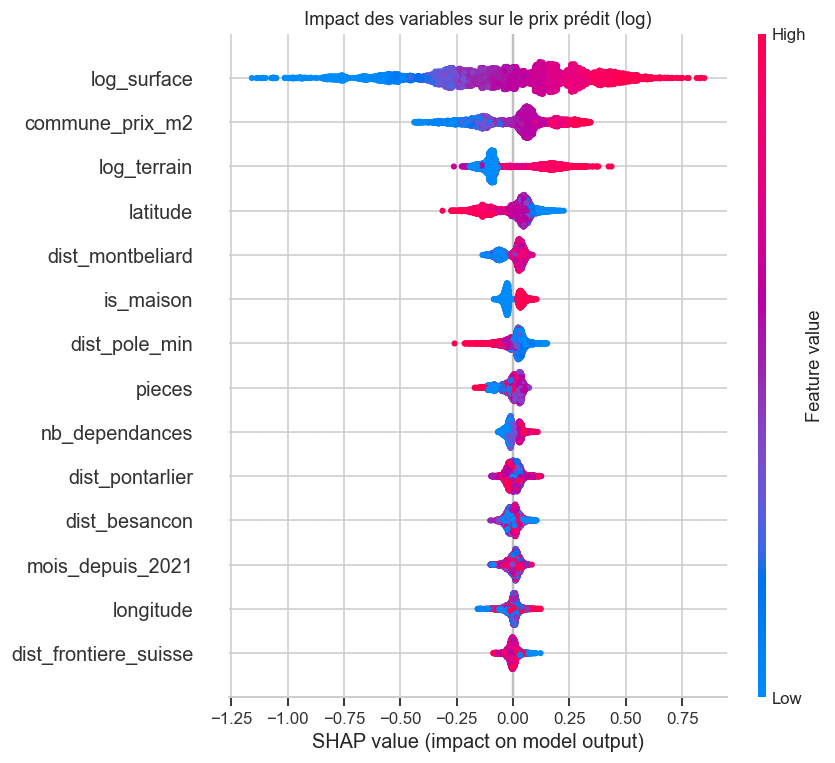

In [13]:
explainer = shap.TreeExplainer(gbm)
sv = explainer.shap_values(Xte)
shap.summary_plot(sv, Xte, show=False, max_display=14)
plt.title('Impact des variables sur le prix prédit (log)'); plt.tight_layout(); plt.show()

In [14]:
imp = pd.Series(np.abs(sv).mean(axis=0), index=FEATURES).sort_values(ascending=False)
(imp/imp.sum()*100).round(1).rename('Importance (%)').to_frame()

,Importance (%)
log_surface,30.9
commune_prix_m2,15.1
log_terrain,14.8
latitude,8.5
dist_montbeliard,4.8
is_maison,4.2
dist_pole_min,4.2
pieces,3.6
nb_dependances,2.7
dist_pontarlier,2.6


**Lecture :**
- La **surface** est le premier facteur (30,9 %), suivie de la **localisation** (prix au m² de la commune, latitude, distances) et du **terrain** (14,8 %). À eux trois, surface, prix de la commune et terrain pèsent environ 60 % de l'importance.
- La latitude et la distance à Montbéliard captent sans doute l'écart entre le nord du département (prix plus bas) et le sud, le Haut-Doubs (prix plus élevés).
- La distance à la frontière suisse pèse peu (1,7 %) : son effet est probablement déjà contenu dans le prix de la commune.

## 7. Conclusions
Sur 2025, année jamais vue pendant l'entraînement ni le réglage, le modèle final (**LightGBM**) obtient une erreur absolue moyenne de **≈ 41 000 €** (41 080 €), une erreur relative médiane de **18 %** et un **R² de 0,64**. C'est **12,8 % d'erreur en moins** que la baseline « prix médian de la commune » (47 098 €).
- En euros, l'erreur est presque deux fois plus élevée pour les maisons que pour les appartements (MAE 56 405 € contre 29 168 €), mais le R² est proche (0,57 contre 0,60).
- La surface, le prix de la commune et le terrain sont les trois variables les plus importantes (SHAP).
- Le test n'est filtré que sur le périmètre de l'étude (biens de 20 000 € à 1,5 M€) : le filtre sur le prix au m² ne s'applique qu'à l'entraînement, donc le score n'est pas flatté par la suppression des ventes atypiques.

**Limites**
- **Périmètre :** les ventes hors de la fourchette 20 000 € – 1,5 M€ ne sont pas évaluées.
- **Validation croisée non temporelle :** l'encodage de la commune et la recherche d'hyperparamètres utilisent des plis mélangés, alors que le test final, lui, est bien temporel.
- **Marché 2025 non capté :** les prix 2025 sont prédits à partir de 2021–2024. Un changement de marché (taux d'intérêt, conjoncture) explique une partie de l'erreur, et les modèles d'arbres n'extrapolent pas la variable de temps (`mois_depuis_2021` prend en 2025 des valeurs jamais vues).
- **Biens chers sous-estimés** (au-dessus de 400 000 €) et **ventes à prix très bas surestimées** (biens à rénover, ventes atypiques).
- Les données ne contiennent ni l'état du bien, ni le DPE, ni l'étage, ni la vue : ils expliquent une grande partie de l'erreur restante.

**Pistes d'amélioration**
- Valider l'encodage de la commune et la recherche d'hyperparamètres par année (`TimeSeriesSplit`) plutôt qu'en plis mélangés.
- Ajouter des données externes (INSEE : revenus et population par commune), des distances aux gares et à la Suisse par route.
- Comparer avec un réseau de neurones (PyTorch) et ajouter un intervalle de prédiction (régression quantile).